In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

from sklearn.model_selection import cross_val_score, cross_val_predict, cross_validate
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.metrics import mean_squared_log_error, r2_score

from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.feature_selection import SelectKBest, SelectPercentile, SelectFromModel
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import mutual_info_regression, f_regression
from sklearn.feature_selection import RFE, RFECV

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# **Read in Data**

In [2]:
X = pd.read_csv('../data/X.csv')
X_train = pd.read_csv('../data/X_train.csv')
X_test = pd.read_csv('../data/X_test.csv')

y = pd.read_csv('../data/y.csv')
y = np.array(y)
y_normalized = MinMaxScaler().fit_transform(y)
y_log = np.array(np.log(y)).reshape(-1, 1)
y_log_normalized = MinMaxScaler().fit_transform(y_log)
y = y.ravel()
y_normalized = y_normalized.ravel()
y_log = y_log.ravel()
y_log_normalized = y_log_normalized.ravel()

y_train = pd.read_csv('../data/y_train.csv')
y_train = np.array(y_train)
y_train_normalized = MinMaxScaler().fit_transform(y_train)
y_train_log = np.array(np.log(y_train)).reshape(-1, 1)
y_train_log_normalized = MinMaxScaler().fit_transform(y_train_log)
y_train = y_train.ravel()
y_train_normalized = y_train_normalized.ravel()
y_train_log = y_train_log.ravel()
y_train_log_normalized = y_train_log_normalized.ravel()

y_test = pd.read_csv('../data/y_test.csv')
y_test = np.array(y_test)
y_test_normalized = MinMaxScaler().fit_transform(y_test)
y_test_log = np.array(np.log(y_test)).reshape(-1, 1)
y_test_log_normalized = MinMaxScaler().fit_transform(y_test_log)
y_test = y_test.ravel()
y_test_normalized = y_test_normalized.ravel()
y_test_log = y_test_log.ravel()
y_test_log_normalized = y_test_log_normalized.ravel()

# **Remove Features with 0 Variance**

In [3]:
sel = VarianceThreshold(threshold=0)
sel.fit(X_train)

print('There are %s number of variables with 0 variance.' % (X_train.shape[1] - sum(sel.get_support())))

columns_to_drop = [x for x in X_train.columns if x not in X_train.columns[sel.get_support()]]
X_train = X_train.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)
X = X.drop(columns=columns_to_drop)

There are 45 number of variables with 0 variance.


In [4]:
print(pd.DataFrame(columns_to_drop, columns=['Zero Variance Variables']).to_latex(index=False))

\begin{tabular}{l}
\toprule
Zero Variance Variables \\
\midrule
                EGYUSED \\
                 ELUSED \\
                  SOHT1 \\
                  COHT2 \\
              OTHTEQ\_FK \\
              OTHTEQ\_PR \\
              BOILER\_CO \\
              OTHTEQ\_CO \\
               PKGHT\_OT \\
             BLRAIR\_CO2 \\
            BLRFNCL\_CO2 \\
            BLRDUCT\_CO2 \\
             BLRRAD\_CO2 \\
            BLRRDFL\_CO2 \\
            BLRWTLP\_CO2 \\
             BLROTD\_CO2 \\
            BLRFNCL\_OT2 \\
            BLRDUCT\_OT2 \\
             BLRRAD\_OT2 \\
            BLRRDFL\_OT2 \\
            BLRWTLP\_OT2 \\
             BLROTD\_OT2 \\
               OTHTP\_FK \\
               OTHTP\_PR \\
               BOILP\_CO \\
               OTHTP\_CO \\
               PKGHP\_OT \\
              OTCLEQ\_NG \\
              OTCLEQ\_FK \\
              OTCLEQ\_PR \\
              OTCLEQ\_ST \\
               OTCLP\_NG \\
               OTCLP\_FK \\
               O

# **Use F-statistic to Choose Most Correlated Features**

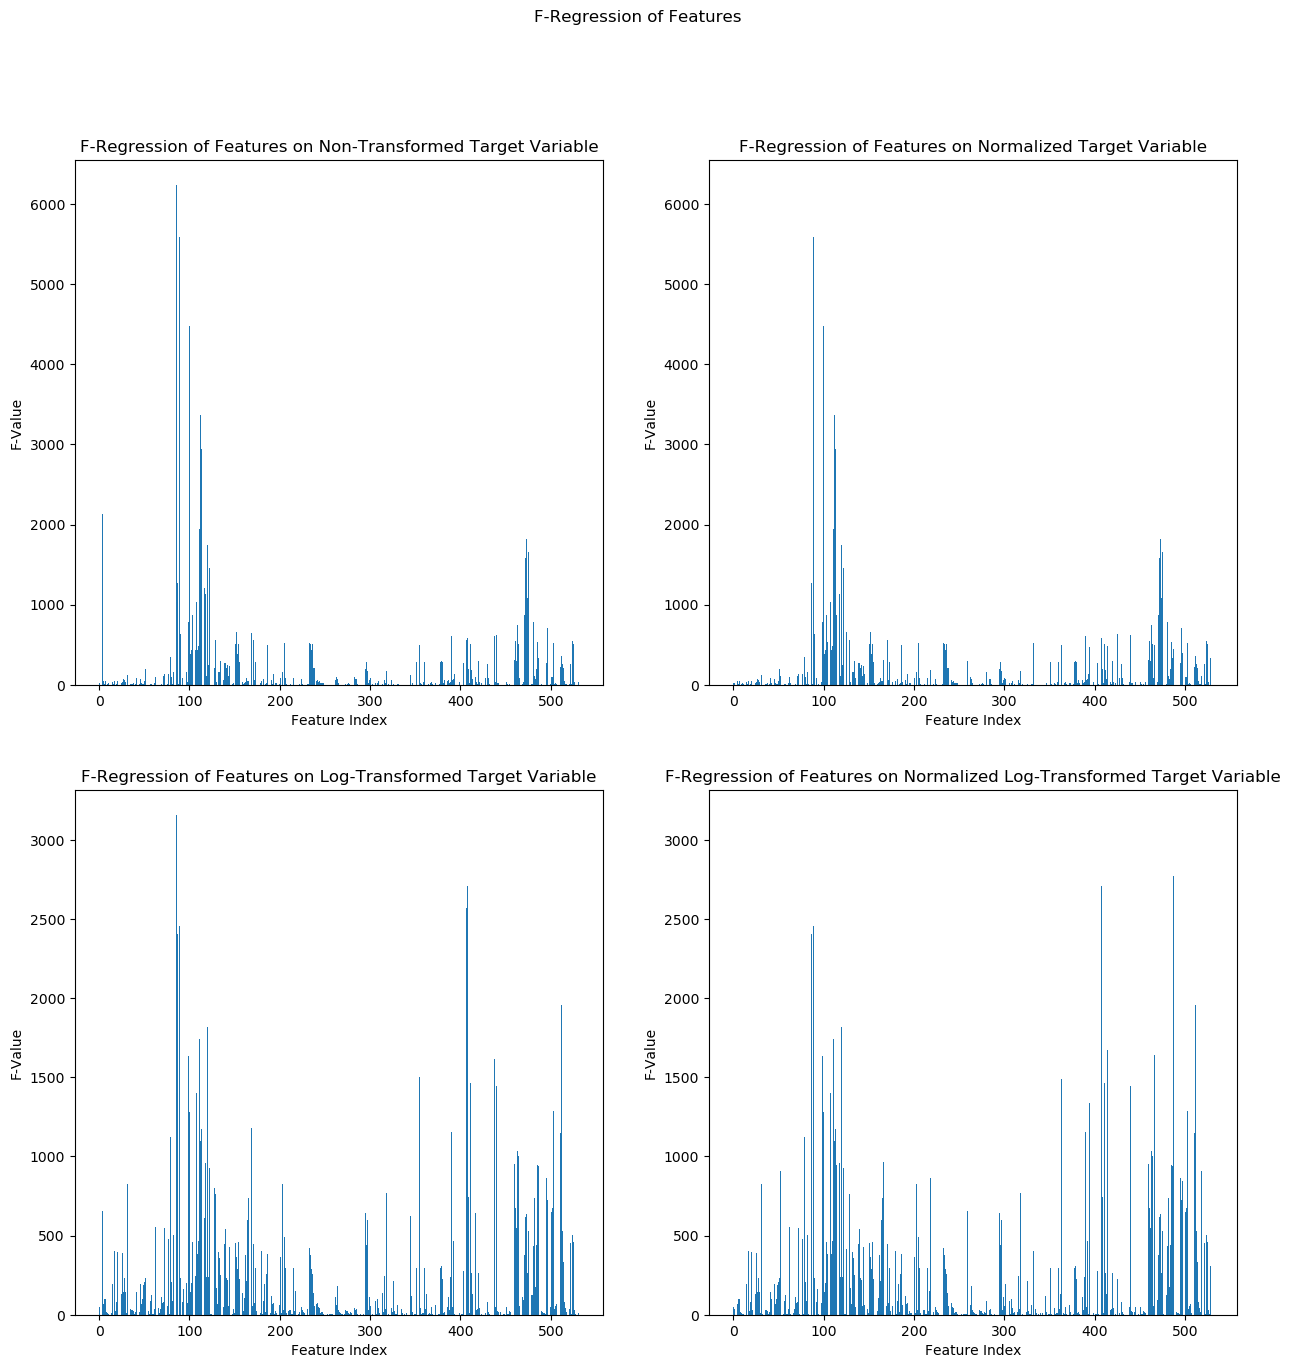

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15,15))
axes = axes.ravel()

i = 0
for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):
    
    f_selector = SelectKBest(score_func=f_regression, k='all')
    f_selector.fit_transform(X_train, target)
    
    axes[i].bar([j for j in range(len(f_selector.scores_))], f_selector.scores_)
    axes[i].set_xlabel('Feature Index')
    axes[i].set_ylabel('F-Value')
    axes[i].set_title(f'F-Regression of Features on {title} Target Variable')
    
    i += 1
    
plt.suptitle('F-Regression of Features')
plt.savefig('../images/featureselection_fvalues.png', dpi=300)

In [6]:
selectedfeatures_fregression_10best = {}

for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):

    f_selector = SelectKBest(f_regression, k=10)
    f_selector.fit_transform(X_train, target)
    selectedfeatures_fregression_10best[title] = f_selector.get_feature_names_out()

selectedfeatures_fregression_10best = pd.DataFrame(selectedfeatures_fregression_10best)
print(selectedfeatures_fregression_10best.to_latex(index=False))

\begin{tabular}{llll}
\toprule
        Non-Transformed &              Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
PBA\_INPATIENTHEALTHCARE & PBA\_INPATIENTHEALTHCARE &            SQFT &                       SQFT \\
                   SQFT &                    SQFT &          NFLOOR &                     NFLOOR \\
                 NELVTR &                  NELVTR &          NELVTR &                     NELVTR \\
                  HCBED &                   HCBED &        TVVIDEON &                   TVVIDEON \\
                  NWKER &                   NWKER &            EMCS &                       EMCS \\
                  XRAYN &                   XRAYN &          EMCSHT &                     EMCSHT \\
                 RFGVNN &                  RFGVNN &          EMCSCL &                     EMCSCL \\
                 RFGICN &                  RFGICN &          RFGVEN &                     RFGVEN \\
                PCTERMN &                 PCTERMN &       

In [7]:
selectedfeatures_fregression_5percentile = {}

for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):

    f_selector = SelectPercentile(f_regression, percentile=5)
    f_selector.fit_transform(X_train, target)
    selectedfeatures_fregression_5percentile[title] = f_selector.get_feature_names_out()

selectedfeatures_fregression_5percentile = pd.DataFrame(selectedfeatures_fregression_5percentile)
print(selectedfeatures_fregression_5percentile.to_latex(index=False))

\begin{tabular}{llll}
\toprule
        Non-Transformed &              Normalized &      Log-Transformed & Normalized Log-Transformed \\
\midrule
PBA\_INPATIENTHEALTHCARE & PBA\_INPATIENTHEALTHCARE & HWRDHT\_NOTAPPLICABLE &       HWRDHT\_NOTAPPLICABLE \\
                   SQFT &                    SQFT &                 SQFT &                       SQFT \\
                 NFLOOR &                  NFLOOR &               NFLOOR &                     NFLOOR \\
                 NELVTR &                  NELVTR &               NELVTR &                     NELVTR \\
                  HCBED &                   HCBED &                WKHRS &                      WKHRS \\
                  WKHRS &                   WKHRS &               RFGWIN &                     RFGWIN \\
                  NWKER &                   NWKER &               RFGVNN &                     RFGVNN \\
                  CAFSF &                   CAFSF &             TVVIDEON &                   TVVIDEON \\
           

# **Use Mutual Information to Choose Most Correlated Features**

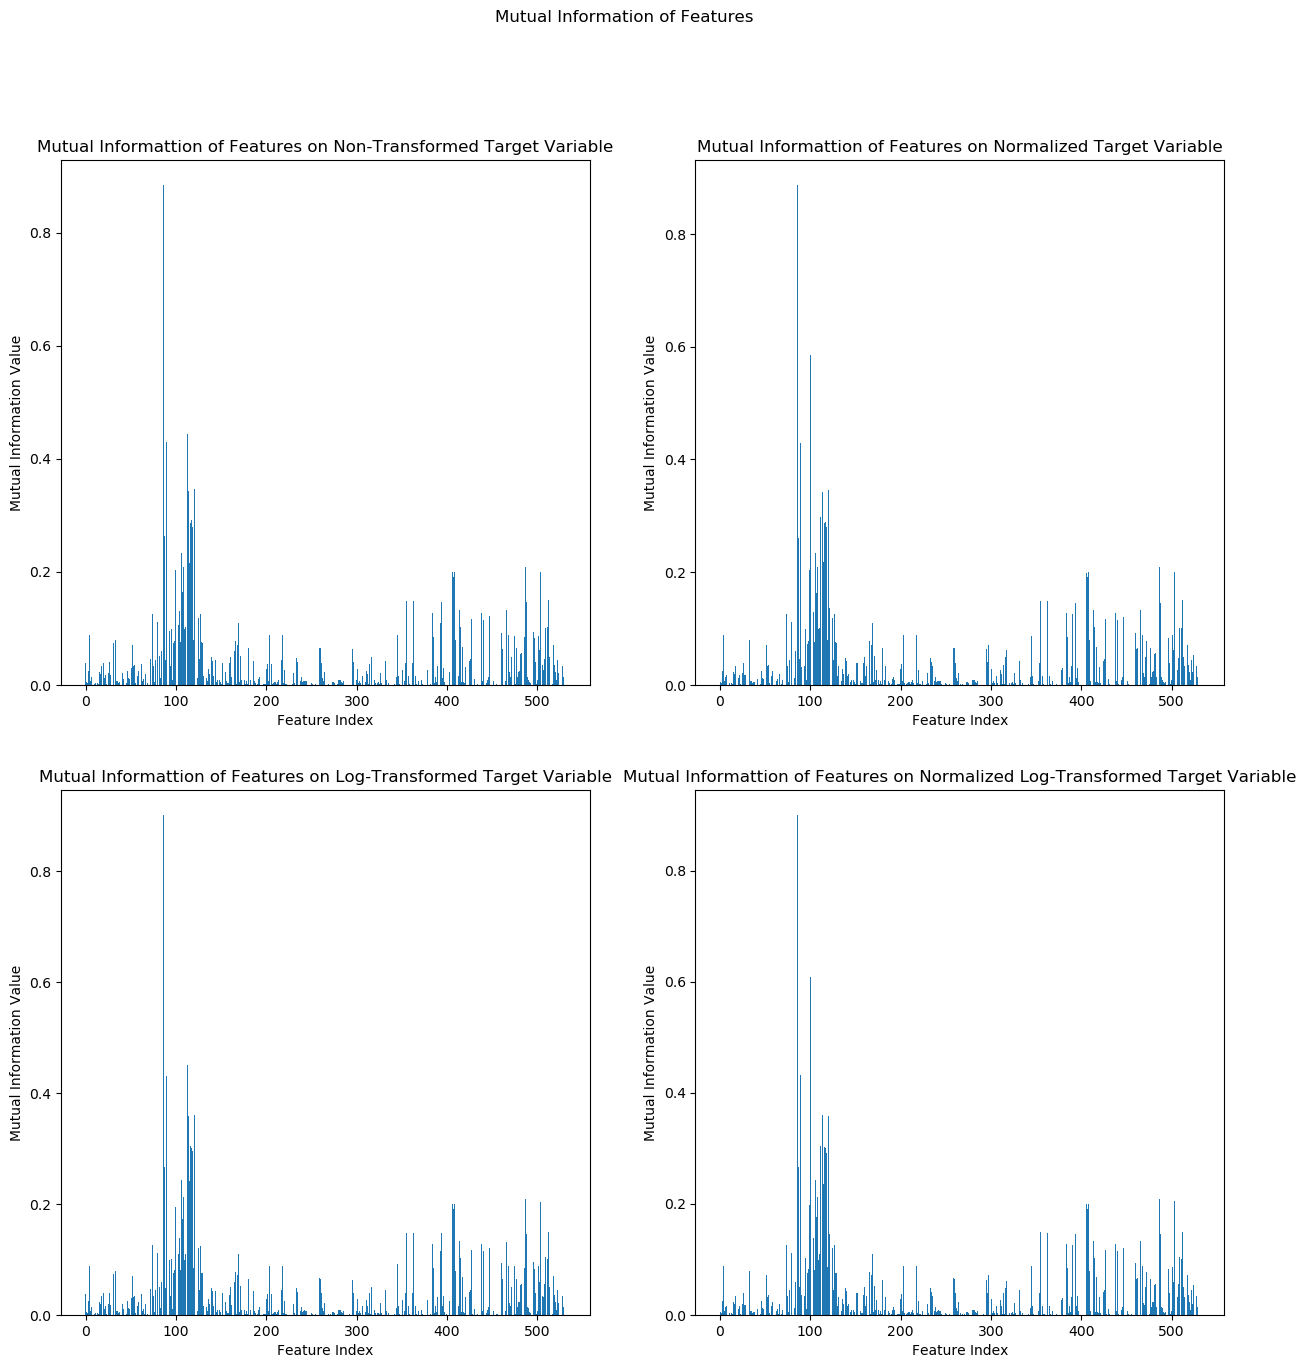

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15,15))
axes = axes.ravel()


i = 0
for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):
    
    mi_selector = SelectKBest(score_func=mutual_info_regression, k='all')
    mi_selector.fit_transform(X_train, target)
    
    axes[i].bar([j for j in range(len(mi_selector.scores_))], mi_selector.scores_)
    axes[i].set_xlabel('Feature Index')
    axes[i].set_ylabel('Mutual Information Value')
    axes[i].set_title(f'Mutual Informattion of Features on {title} Target Variable')
    
    i += 1
    
plt.suptitle('Mutual Information of Features')
plt.savefig('../images/featureselection_mivalues.png', dpi=300)

In [9]:
selectedfeatures_minfo_10best = {}

for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):

    mi_selector = SelectKBest(mutual_info_regression, k=10)
    mi_selector.fit_transform(X_train, target)
    selectedfeatures_minfo_10best[title] = mi_selector.get_feature_names_out()

selectedfeatures_minfo_10best = pd.DataFrame(selectedfeatures_minfo_10best)
print(selectedfeatures_minfo_10best.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Non-Transformed & Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
           SQFT &       SQFT &            SQFT &                       SQFT \\
         NELVTR &     NELVTR &          NELVTR &                     NELVTR \\
          NWKER &      NWKER &           NWKER &                      NWKER \\
         RFGVNN &     RFGVNN &          RFGVNN &                     RFGVNN \\
        PCTERMN &    PCTERMN &         PCTERMN &                    PCTERMN \\
         LAPTPN &     LAPTPN &          LAPTPN &                     LAPTPN \\
        SERVERN &    SERVERN &         SERVERN &                    SERVERN \\
      LGOFFDEVN &  LGOFFDEVN &       LGOFFDEVN &                  LGOFFDEVN \\
       TVVIDEON &   TVVIDEON &        TVVIDEON &                   TVVIDEON \\
          PKLTN &      PKLTN &           PKLTN &                      PKLTN \\
\bottomrule
\end{tabular}



In [10]:
selectedfeatures_minfo_5percentile = {}

for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):

    mi_selector = SelectPercentile(mutual_info_regression, percentile=5)
    mi_selector.fit_transform(X_train, target)
    selectedfeatures_minfo_5percentile[title] = mi_selector.get_feature_names_out()

selectedfeatures_minfo_5percentile = pd.DataFrame(selectedfeatures_minfo_5percentile)
print(selectedfeatures_minfo_5percentile.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Non-Transformed & Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
           SQFT &       SQFT &            SQFT &                       SQFT \\
         NFLOOR &     NFLOOR &          NFLOOR &                     NFLOOR \\
         NELVTR &     NELVTR &          NELVTR &                     NELVTR \\
          WKHRS &      WKHRS &           WKHRS &                      WKHRS \\
          NWKER &      NWKER &           NWKER &                      NWKER \\
         RFGRSN &     RFGRSN &          RFGRSN &                     RFGRSN \\
       RFGCOMPN &   RFGCOMPN &        RFGCOMPN &                   RFGCOMPN \\
         RFGWIN &     RFGWIN &          RFGWIN &                     RFGWIN \\
         RFGVNN &     RFGVNN &          RFGVNN &                     RFGVNN \\
         RFGICN &     RFGICN &          RFGICN &                     RFGICN \\
        PCTERMN &    PCTERMN &         PCTERMN &                    PCTERMN \\
         LAP

# **Use a Lasso Regression to Remove Features**

In [11]:
lasso_selection = SelectFromModel(Lasso(alpha=.001))
lasso_selection.fit(X_train, y_train_normalized);

selected_features = X_train.columns[(lasso_selection.get_support())]
print('Total features: %s' % X_train.shape[1])
print('Selected features: %s' % len(selected_features))
print('Features with coefficients shrunk to zero: %s' % np.sum(lasso_selection.estimator_.coef_ == 0))

# columns_to_drop = [x for x in X_train.columns if x not in X_train.columns[lasso_selection.get_support()]]
# X_train = X_train.drop(columns=columns_to_drop)
# X_test = X_test.drop(columns=columns_to_drop)
# X = X.drop(columns=columns_to_drop)

print(pd.DataFrame(X_train.columns[lasso_selection.get_support()], columns=['Lasso Selected Variables']).to_latex(index=False))

Total features: 532
Selected features: 49
Features with coefficients shrunk to zero: 475
\begin{tabular}{l}
\toprule
Lasso Selected Variables \\
\midrule
                    SQFT \\
                  NELVTR \\
                   HCBED \\
                 PUBCLIM \\
                  GLSSPC \\
                 BASEMNT \\
                  YRCONC \\
                  MONUSE \\
                 OCCUPYP \\
                BOILP\_EL \\
                HTPHP\_EL \\
              REHEATP\_EL \\
                OTHTP\_EL \\
                FURNP\_NG \\
                PKGHP\_NG \\
                BOILP\_NG \\
               SLFCNP\_NG \\
                BOILP\_FK \\
                FURNP\_PR \\
                STHWP\_ST \\
                STHWP\_HW \\
                   COOLP \\
                RCACP\_EL \\
                PKGCP\_EL \\
                CHILP\_EL \\
                HTPCP\_EL \\
               ACWNWP\_EL \\
                EVAPP\_EL \\
                OTCLP\_EL \\
               

# **Use Random Forest Feature Importance to Select Features**

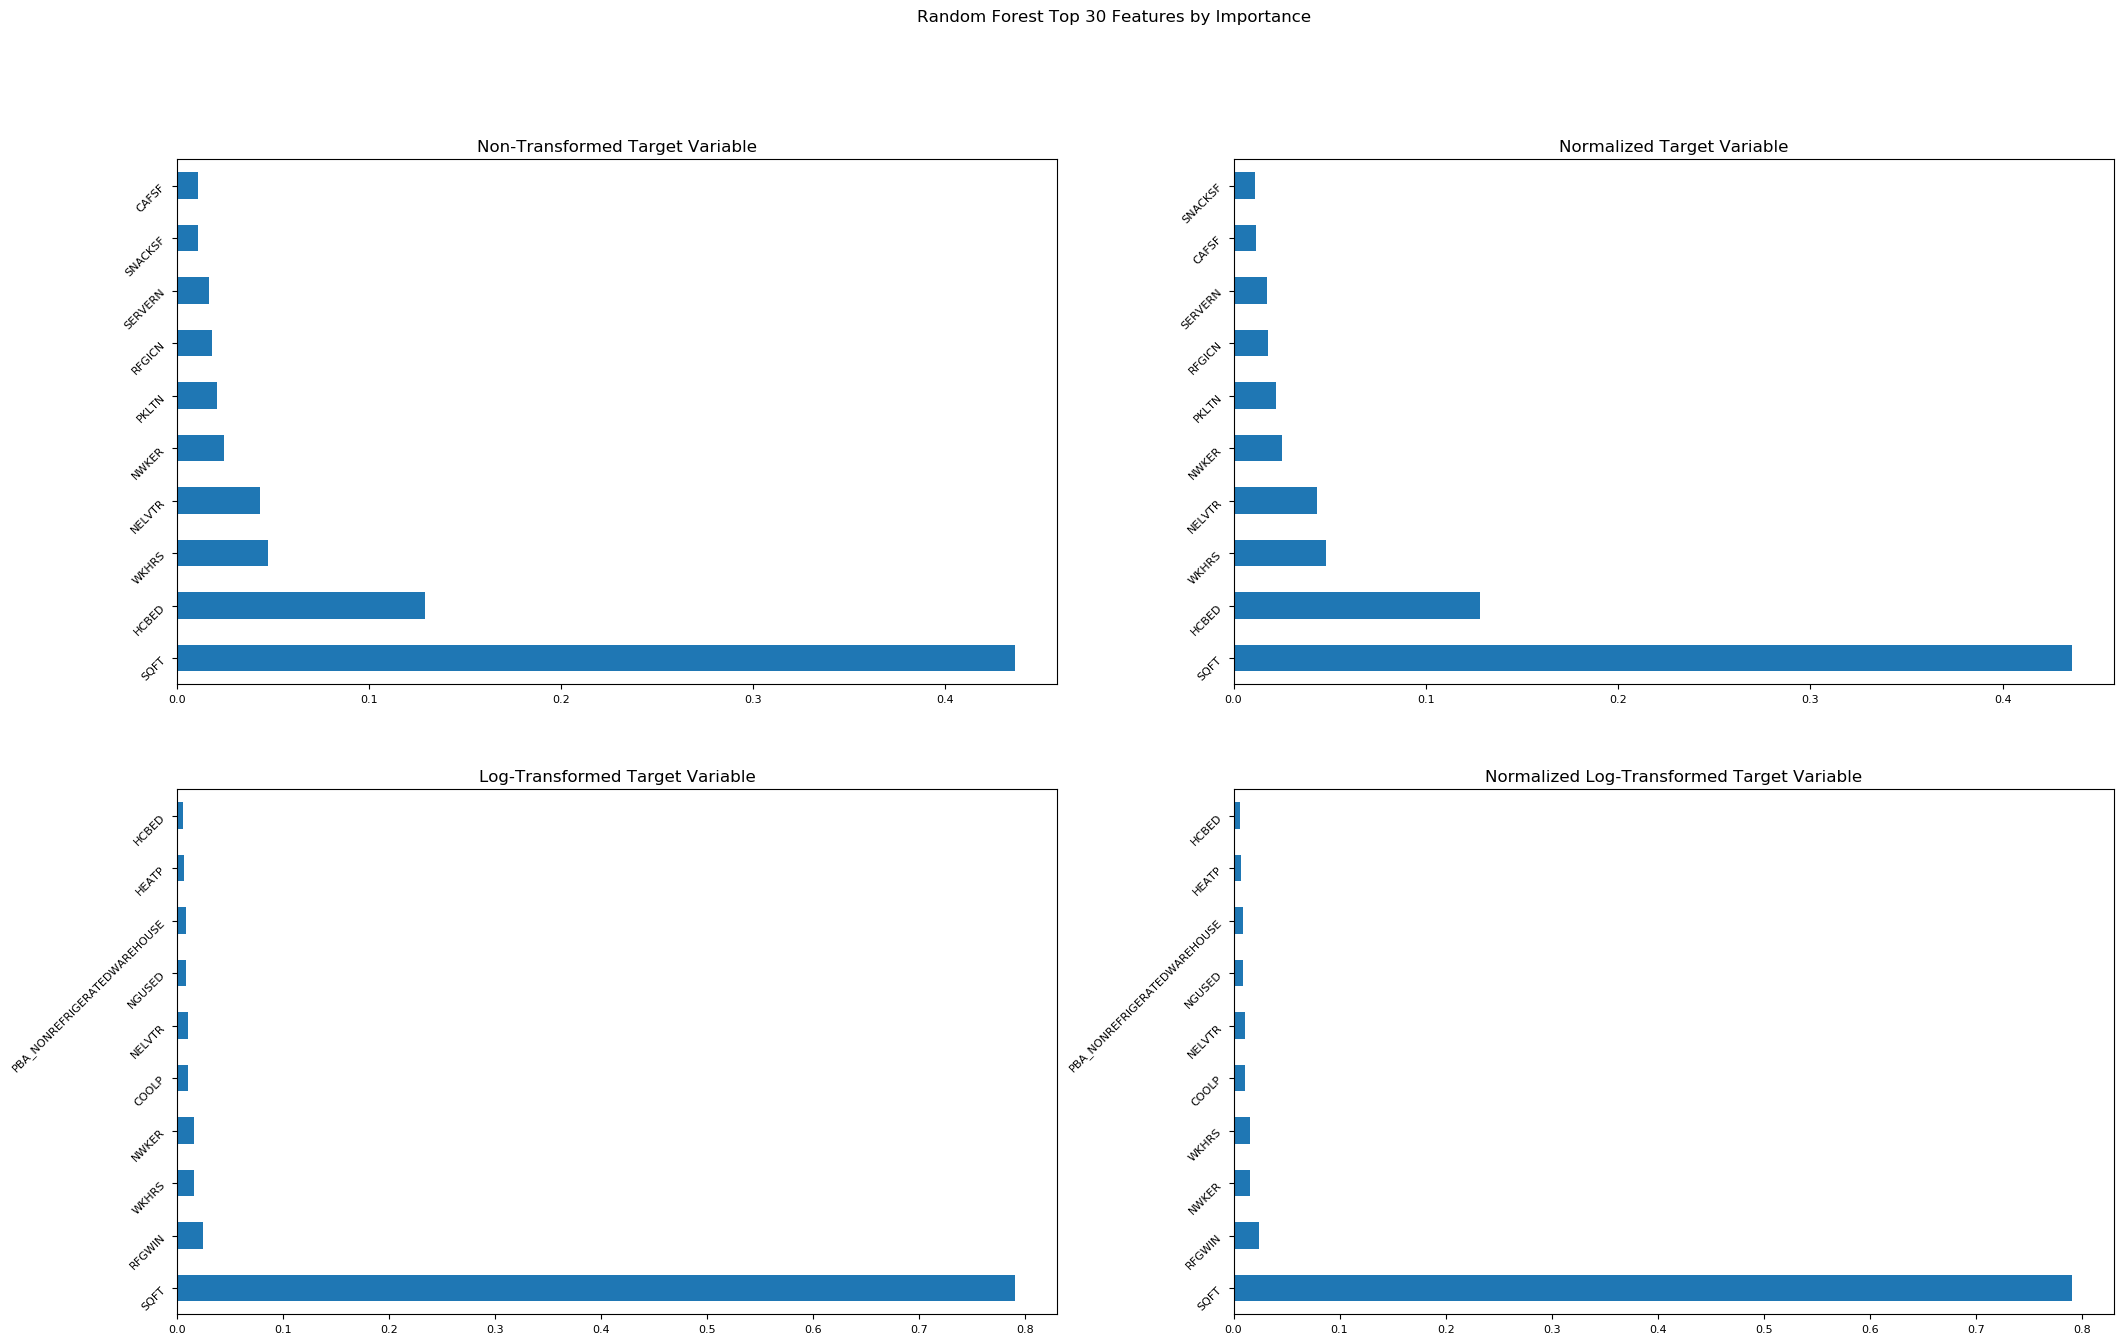

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(25,15))
axes = axes.ravel()


all_feature_importances = {}

i = 0
for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):

    rfr = RandomForestRegressor(n_jobs=-1, random_state=42)
    rfr.fit(X_train, target)
    importances = rfr.feature_importances_
    
    feat_importances = pd.Series(rfr.feature_importances_, index= X_train.columns)
    all_feature_importances[title] = feat_importances.nlargest(10).index.tolist()

    feat_importances.nlargest(10).plot(kind='barh', ax=axes[i], rot=45, fontsize=8);
    axes[i].set_title(f'{title} Target Variable')
    
    
    i += 1
    
plt.suptitle('Random Forest Top 30 Features by Importance')
plt.savefig('../images/featureselection_rffeatureimportances.png', dpi=300)

all_feature_importances = pd.DataFrame(all_feature_importances)

# **Use Recursive Feature Elimination with Cross Validation to Select Features**

WARNING: This takes a VERY long time. 

In [14]:
all_top_features = {}

for target, title in zip([y_train, y_train_normalized, y_train_log, y_train_log_normalized], 
                         ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']):
    
    rfr = RandomForestRegressor(n_jobs=-1, random_state=42)
    selector = RFE(rfr, n_features_to_select=10, step=5)
    selector = selector.fit(X_train, target)
    
    features = pd.DataFrame({'Feature':selector.feature_names_in_, 'Ranking':selector.ranking_})
    features = features[features.Ranking == 1].Feature.tolist()
    
    all_top_features[title] = features
    
all_top_features = pd.DataFrame(all_top_features)
print(all_top_features.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Non-Transformed & Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
           SQFT &       SQFT &            SQFT &                       SQFT \\
         NELVTR &     NELVTR &          NELVTR &                     NELVTR \\
          HCBED &      HCBED &           WKHRS &                      WKHRS \\
          WKHRS &      WKHRS &           NWKER &                      NWKER \\
          NWKER &      NWKER &          RFGWIN &                     RFGWIN \\
        SNACKSF &    SNACKSF &           HDD65 &                      HDD65 \\
          CAFSF &      CAFSF &           CDD65 &                      CDD65 \\
         RFGICN &     RFGICN &          NGUSED &                     NGUSED \\
        SERVERN &    SERVERN &           COOLP &                      COOLP \\
          PKLTN &      PKLTN &          LTOHRP &                     LTOHRP \\
\bottomrule
\end{tabular}



# **Find Features Common to All Methods**

In [15]:
def IntersecOf3Sets(arr1, arr2, arr3):
    s1 = set(arr1)
    s2 = set(arr2)
    s3 = set(arr3)
    set1 = s1.intersection(s2) 
    result_set = set1.intersection(s3)
    final_list = list(result_set)
    
    return final_list
    
def IntersecOf2Sets(arr1, arr2):
    s1 = set(arr1)
    s2 = set(arr2)
    result_set = s1.intersection(s2)        
    final_list = list(result_set)
    
    return final_list

In [16]:
common_features = {}

for title in ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']:
    
    common_features[title] = IntersecOf2Sets(all_feature_importances[title].tolist(), all_top_features[title].tolist())

common_features = pd.DataFrame(dict([(k,pd.Series(v)) for k,v in common_features.items() ]))
print(common_features.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Non-Transformed & Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
          NWKER &      NWKER &          NGUSED &                     NGUSED \\
          WKHRS &      WKHRS &           NWKER &                      NWKER \\
         RFGICN &     RFGICN &           WKHRS &                      WKHRS \\
          CAFSF &      CAFSF &          RFGWIN &                     RFGWIN \\
         NELVTR &     NELVTR &           COOLP &                      COOLP \\
          HCBED &      HCBED &          NELVTR &                     NELVTR \\
           SQFT &       SQFT &            SQFT &                       SQFT \\
          PKLTN &      PKLTN &             NaN &                        NaN \\
        SERVERN &    SERVERN &             NaN &                        NaN \\
        SNACKSF &    SNACKSF &             NaN &                        NaN \\
\bottomrule
\end{tabular}



# **Look for any Multicollinearity with a Correlation Matrix**

In [17]:
for title in ['Non-Transformed', 'Normalized', 'Log-Transformed', 'Normalized Log-Transformed']:

    cor = X[common_features[title].dropna().tolist()].corr()

    # plt.figure(figsize=(20,20));
    # ax = sns.heatmap(cor, annot=True);
    # bottom, top = ax.get_ylim()
    # ax.set_ylim(bottom + 0.5, top - 0.5)
    # plt.savefig('../images/correlation_matrix.png', dpi=300)

    upper = cor.where(np.triu(np.ones(cor.shape), k=1).astype(np.bool))
    collinear_features = [column for column in upper.columns if any(upper[column] > 0.9)]

    if collinear_features:
        print(title, collinear_features)
        
    for feature in collinear_features:
        common_features[title] = common_features[title].replace({feature:np.nan})

In [18]:
print(common_features.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Non-Transformed & Normalized & Log-Transformed & Normalized Log-Transformed \\
\midrule
          NWKER &      NWKER &          NGUSED &                     NGUSED \\
          WKHRS &      WKHRS &           NWKER &                      NWKER \\
         RFGICN &     RFGICN &           WKHRS &                      WKHRS \\
          CAFSF &      CAFSF &          RFGWIN &                     RFGWIN \\
         NELVTR &     NELVTR &           COOLP &                      COOLP \\
          HCBED &      HCBED &          NELVTR &                     NELVTR \\
           SQFT &       SQFT &            SQFT &                       SQFT \\
          PKLTN &      PKLTN &             NaN &                        NaN \\
        SERVERN &    SERVERN &             NaN &                        NaN \\
        SNACKSF &    SNACKSF &             NaN &                        NaN \\
\bottomrule
\end{tabular}



# **Save Selected Features**

In [19]:
pd.DataFrame(common_features).to_csv('../data/selected_features.csv', index=False)